In [1]:
import numpy as np
import pandas as pd
import os
import torch
import matplotlib.pyplot as plt
import random
from functools import partial
import time

from fontTools.misc.bezierTools import epsilon
from torch.utils.data import Dataset, DataLoader
from torch.utils.data import TensorDataset
from tqdm.notebook import tqdm

# from notebooks.examine_toy_networks import cluster_sizes
from scipy.stats import dirichlet, multinomial
from src.model_toy_data import Model

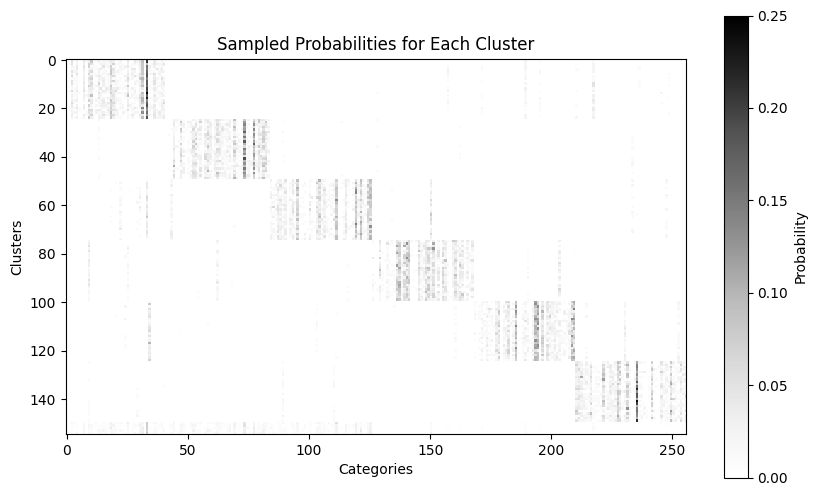

In [2]:
k = 4
kmer_num = 4 ** k
clusters_num = 6
sequence_length = 100 # Number of trials
cluster_sizes = [25]*clusters_num
sequence_num = sum(cluster_sizes)
epsilon = 1e-2

# Construct Dirichlet Prior
# Each cluster has higher concentration on its own dimensions
alphas = np.ones(shape=(clusters_num, kmer_num))*epsilon
dim_count_per_cluster = kmer_num // clusters_num
for c in range(clusters_num):
    alphas[c, c*dim_count_per_cluster:(c+1)*dim_count_per_cluster] = 1

    if c == clusters_num - 1:  # Last cluster takes the rest
        alphas[c, (c+1)*dim_count_per_cluster:] = 1

# Sample probabilities for each cluster
p = np.zeros(shape=(clusters_num, kmer_num))
for c in range(clusters_num):
    p[c, :] = dirichlet.rvs(alphas[c, :], size=1)
p = p / p.sum(axis=1, keepdims=True)  # Normalize to ensure they sum to 1

# Now sample the k-mer counts from the multinomial distribution for each cluster
# The first cluster_sizes[0] points come from cluster 0, next cluster_sizes[1] points come from cluster 1, and so on.
kmer_counts = np.zeros(shape=(sequence_num, kmer_num), dtype=float)
start = 0
for c in range(clusters_num):
    end = start + cluster_sizes[c]
    kmer_counts[start:end, :] = multinomial.rvs(sequence_length, p[c, :], size=cluster_sizes[c] )
    start = end
kmer_counts = kmer_counts / kmer_counts.sum(axis=1, keepdims=True)  # Normalize each row to sum to 1


# Construct pairs by taking two samples from the same cluster
pairs = []
for c in range(clusters_num):
    start = sum(cluster_sizes[:c])
    end = start + cluster_sizes[c]
    for i in range(start, end):
        for j in range(i + 1, end):
            pairs.append([kmer_counts[i], kmer_counts[j]])

# Add sequences belonging to multiple clusters
new_kmer_counts = np.zeros(shape=(5, kmer_num), dtype=float)
for c in range(3):
    new_kmer_counts += multinomial.rvs(sequence_length, p[c, :], size=5 ).astype(float)
new_kmer_counts = new_kmer_counts / new_kmer_counts.sum(axis=1, keepdims=True)
# Add to the kmer_counts
kmer_counts = np.vstack([kmer_counts, new_kmer_counts])

# Add pairs for the new sequences
for c in range(3):
    start = sum(cluster_sizes[:c])
    end = start + cluster_sizes[c]
    for i in range(start, end):
        for j in range(5):
            pairs.append([kmer_counts[i], kmer_counts[-j-1]])

# # Assing the last 3 sequences to random clusters by taking random samples from the clusters
# kmer_counts[-1] = ( kmer_counts[2] + kmer_counts[32] + kmer_counts[42] ) / 3.
# kmer_counts[-2] = ( kmer_counts[12] + kmer_counts[37] + kmer_counts[65] ) / 3.
# kmer_counts[-3] = np.ones_like(kmer_counts[-3]) / kmer_counts.shape[1] #( kmer_counts[5] + kmer_counts[35] + kmer_counts[68] ) / 3.

# Plot the sampled probabilities
plt.figure(figsize=(10, 6))
plt.imshow(kmer_counts, cmap='Greys', interpolation='none')
plt.colorbar(label='Probability')
plt.title('Sampled Probabilities for Each Cluster')
plt.xlabel('Categories')
plt.ylabel('Clusters')
plt.show()


# Write the pairs to a CSV file
output_file = os.path.join(os.getcwd(), '..', 'dataset', 'toy_kmer_data.csv')
with open(output_file, 'w') as f:
    for left_kmer, right_kmer in pairs:
        left_kmer_str = ' '.join(map(str, left_kmer))
        right_kmer_str = ' '.join(map(str, right_kmer))
        f.write(f"{left_kmer_str},{right_kmer_str}\n")

In [3]:
print(clusters_num)
print(sum(cluster_sizes[:5]))

6
125


In [4]:
# # For each cluster, build its own Markov transition matrix
# # Firstly, construct a matrix indicating valid transitions from one k-mer to another
# def build_transition_mask(k):
#     kmer_counts = 4 ** k
#     transition_mask = np.zeros((kmer_counts, kmer_counts), dtype=bool)
#     for i in range(kmer_counts):
#         prefix = i % (4 ** (k - 1))  # Get the last k-1 digits in base 4
#         for j in range(4):
#             next_kmer = prefix * 4 + j  # Shift left and add new digit
#             transition_mask[i, next_kmer] = True
#     return transition_mask
#
# # For each cluster, build its own transition matrix so that it has higher probabilities for certain transitions for each cluster
# def build_transition_matrix(k, clusters_num, dim_count_per_cluster, epsilon=1e-2):
#     kmer_counts = 4 ** k
#     transition_matrices = np.zeros((clusters_num, kmer_counts, kmer_counts), dtype=float)
#     transition_mask = build_transition_mask(k)
#     for c in range(clusters_num):
#         for i in range(kmer_counts):
#             valid_transitions = np.where(transition_mask[i])[0]
#             transition_probs = np.ones(len(valid_transitions)) * epsilon
#             # Increase probabilities for transitions within the cluster's dimension range
#             cluster_start = c * dim_count_per_cluster
#             cluster_end = (c + 1) * dim_count_per_cluster if c != clusters_num - 1 else kmer_counts
#             for idx, next_kmer in enumerate(valid_transitions):
#                 if cluster_start <= next_kmer < cluster_end:
#                     transition_probs[idx] += 1.0  # Increase probability for cluster-specific transitions
#             transition_probs /= transition_probs.sum()  # Normalize to sum to 1
#             transition_matrices[c, i, valid_transitions] = transition_probs
#     return transition_matrices

In [10]:
# Train the model
import os
import sys
import torch
# from src.model_toy_data import Model

K=4
out_dim = 2
neg_sample_per_pos = 2 #200
max_seq_num = 0
epoch_num = 40 #20
lr = 0.001
batch_size = 100
save_every = 0
device = "mps"
strategy = "sequential" #"mean_only"
seed = 1

input_file_path = os.path.join(os.getcwd(), '..', 'dataset', 'toy_kmer_data.csv')
model_file_path = os.path.join(os.getcwd(), '..', 'notebooks', 'models', 'test.model')

# Run terminal command
cmd=f"python {os.path.join(os.getcwd(), '..', 'src','model_toy_data.py')}"
cmd+=f" --input {input_file_path}"
cmd+=f" --output {model_file_path}"
cmd+=f" --k {k} --out_dim {out_dim} --neg_sample_per_pos {neg_sample_per_pos} --max_seq_num {max_seq_num}"
cmd+=f" --epoch {epoch_num} --lr {lr} --batch_size {batch_size} --save_every {save_every} --distributed 0"
cmd+=f" --device {device} --loss_name mahalanobis --seed {seed} --strategy {strategy}"
# print(cmd)
os.system(f"{cmd}")



+ Information
	- k value: 4
	- Loss name: mahalanobis
	- Epoch number: 40
	- Batch size: 100
	- Learning rate: 0.001
	- Output dimension: 2
	- Negative sample per positive pair: 2
	- Maximum number of sequence pairs to use: 0
	- Learning starting strategy: sequential
	- No distributed training
	- Device: mps
	- Number of data loading workers: 2
	- Seed value: 1
	- Output model name: test.model
+ Reading the data file.
	- File path: /Users/abdulkadircelikkanat/Downloads/kum/notebooks/../dataset/toy_kmer_data.csv
	- Completed in 0.13 seconds.
	- The input file contains: 2175 sequence pairs.
	- For training, 0 sequence pairs will be used.
+ Constructing the indices for positive and negative sample pairs
	- Completed in 0.01 seconds.
	- Training dataset contains 2175 positive pairs.
	- Training dataset contains 4350 negative pairs.
+ Training started.
	- Epoch: 1/40 - Loss: 0.637826225974343 (2.26 secs)
	- Epoch: 2/40 - Loss: 0.414243322430235 (1.39 secs)
	- Epoch: 3/40 - Loss: 0.389596736

0

(155, 2) 150


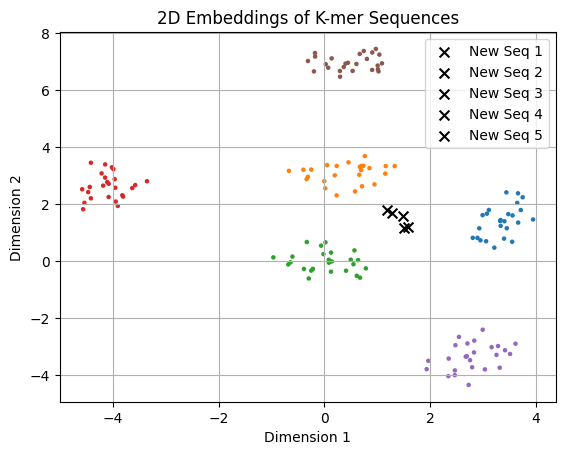

In [11]:
# kmer_sequences = []
# with open(input_file_path, 'r') as f:
#     for line in f:
#         left, right = line.strip().split(',')
#         left = np.asarray(list(map(float, left.split(' '))))
#         right = np.asarray(list(map(float, right.split(' '))))
#         current_kmer = (left + right) / 2.
#         kmer_sequences.append(current_kmer)


# # Load the dataset
# data_path = f"../dataset/plant_sample_{N}_seqs_{K}_clusters.tsv"
# dna_sequences = []
# with open(data_path, "r") as f:
#     for line in f:
#         seq1, seq2 = line.strip().split(",")
#         dna_sequences.append(seq1+seq2)
#
# # Define the model path
# model_path = f"../models/{output_filename}.model" # f"../models/test.model" #
#
# Load the model
kwargs, model_state_dict = torch.load(model_file_path, map_location=torch.device("cpu"))
model = Model(**kwargs)
model.load_state_dict(model_state_dict)
embedding, covs = model.seq2emb(kmer_counts)

print(embedding.shape, sequence_num)


import matplotlib as mpl
import matplotlib.pyplot as plt
plt.figure()
# plt.scatter(embedding[:, 0], embedding[:, 1], s=2)
# Color by cluster
colors = mpl.colormaps['tab10']  # Get a colormap with K distinct colors
cluster_indices = np.array([i // (sequence_num // clusters_num) for i in range(sequence_num)])  # Assuming equal distribution of sequences per cluster
point_colors = colors(cluster_indices)
plt.scatter(embedding[:sequence_num, 0], embedding[:sequence_num, 1], c=point_colors, s=5, alpha=0.99)
plt.title('2D Embeddings of K-mer Sequences')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.grid(True)

# Plot the last 5 sequences with a different marker
for i in range(5):
    plt.scatter(embedding[sequence_num + i, 0], embedding[sequence_num + i, 1], c='black', marker='x', s=50, label=f'New Seq {i+1}')
plt.legend()

plt.show()


#
# # Plot the 2D embeddings
# import matplotlib.pyplot as plt
# import matplotlib as mpl
# import numpy as np
#
# # Create a color map based on the cluster index
# # colors = plt.cm.get_cmap('tab10', K)  # Get a colormap with K distinct colors
# colors = mpl.colormaps['tab10'] #(np.linspace(0, 1, K))
# cluster_indices = np.array([i // (N // K) for i in range(N)])  # Assuming equal distribution of sequences per cluster
# point_colors = colors(cluster_indices)
# plt.figure(figsize=(8, 6))
# plt.scatter(embedding[:, 0], embedding[:, 1], c=point_colors, alpha=0.99)
# plt.title('2D Embeddings of DNA Sequences')
# plt.xlabel('Dimension 1')
# plt.ylabel('Dimension 2')
# plt.grid(True)
# plt.colorbar(ticks=range(K), label='Cluster Index')
# plt.show()

In [12]:
a = [2,3,4,5,6]
print( sum(a[:0]))

0


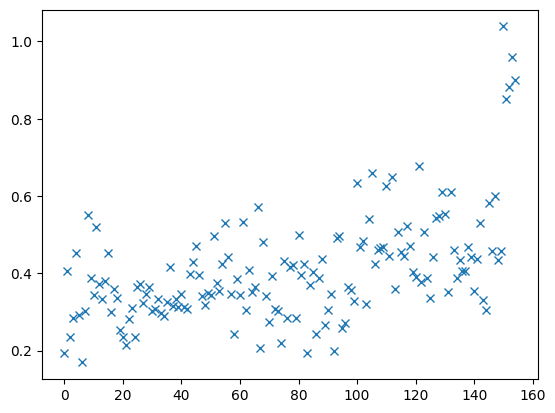

In [19]:
# Plot the distribution of the sequences
plt.figure()
plt.plot(range(covs.shape[0]), covs[:, :].min(axis=-1), 'x', label='Cov Dimension 1')
# plt.plot(range(covs.shape[0]), covs[:, 1], 'o', label='Cov Dimension 2')
plt.show()